# L6 / E12 — 100-Dimensional Corpus-Trained Fasttext + Gaussian Mixture Model (GMM) · K=3

Standalone exploratory experiment following the E0–E7 notebook structure. **This notebook regenerates its own features from redacted tweets using reusable GitHub code** and does not load L1–L5 matrices or assignments. Original sentiment labels are entered **only in Cell #9** after assignments are frozen.

**Research question:** Does changing the clustering algorithm improve sentiment recovery relative to the earlier K-means results, while holding the underlying representation family constant as far as practical?

**Representation:** 100-dimensional corpus-trained FastText. **Algorithm:** Gaussian Mixture Model (GMM). **Clusters:** 3. **Seed:** 5001 for stochastic steps.

**Important comparison qualification:** The FastText embedding dimensions are retained, enabling a closer representation-matched comparison with K-means (though the clustering objective and distance assumptions differ).

**Exploratory status:** These combinations were chosen after observing E0–E7 external scores. Results on the same labels are descriptive and are not an untouched independent evaluation.


In [1]:
# 1 — Environment: install dependencies for GitHub source imports
%pip -q install emoji num2words wordninja wordfreq symspellpy "spacy>=3.7" "scikit-learn>=1.4" "scipy>=1.11" "vaderSentiment==3.3.2" "gensim>=4.3.3"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 541.6/541.6 kB 2.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.0/126.0 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 610.9/610.9 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.5/163.5 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.8/56.8 MB 10.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.6/2.6 MB 32.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 24.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 183.1/183.1 kB 8.0 MB/s eta 0:00:00


**Execution notes:** This notebook uses the existing repository's preprocessing/feature-generation code but independently regenerates every matrix. Clustering is label-blind. Run cells sequentially in Colab. Do not load original sentiment annotations until Cell #9. Agglomerative clustering may require high RAM and considerable time for 14,639 rows. No files are committed to GitHub.


In [2]:
# 2 — Inputs and output destination. Change only these paths.
from pathlib import Path
from google.colab import drive
drive.mount('/content/drive')

INPUT_CSV = Path('/content/drive/MyDrive/MSI5001 project/EDA/Tweets-redacted.csv')
OUTPUT_DIR = Path('/content/drive/MyDrive/MSI5001 project/EDA/L6-externaleval/E12')
assert INPUT_CSV.is_file(), f'Missing redacted CSV: {INPUT_CSV}'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print('Input:', INPUT_CSV)
print('Output:', OUTPUT_DIR)


Mounted at /content/drive
Input: /content/drive/MyDrive/MSI5001 project/EDA/Tweets-redacted.csv
Output: /content/drive/MyDrive/MSI5001 project/EDA/L6-externaleval/E12


In [3]:
# 3 — Fresh GitHub source checkout; never import old generated matrices.
import subprocess
REPO_DIR = Path('/content/l6_source_code')
if REPO_DIR.exists():
    assert (REPO_DIR / '.git').is_dir(), 'Unexpected checkout directory; start a fresh Colab runtime'
else:
    subprocess.run(['git', 'clone', '--depth', '1', 'https://github.com/frankie-chew-nus/sentiment-clustering-ml.git', str(REPO_DIR)], check=True)
GIT_REVISION = subprocess.check_output(['git', '-C', str(REPO_DIR), 'rev-parse', 'HEAD'], text=True).strip()
import sys
sys.path.insert(0, str(REPO_DIR))
from preprocessing import preprocess_text
print('Git revision:', GIT_REVISION)


Git revision: 214b65610fcde724ebf1cbcb8d7ab889347512e6


In [4]:
# 4 — Read ONLY original tweet text. Never read labels in the clustering stage.
import pandas as pd, numpy as np, hashlib, json, platform, importlib.metadata as im

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for block in iter(lambda: f.read(1024*1024), b''):
            h.update(block)
    return h.hexdigest()

raw = pd.read_csv(INPUT_CSV, usecols=['text'], dtype={'text':'string'})
assert raw['text'].notna().all(), 'Null text found'
assert len(raw) == 14639, f'Unexpected corpus size: {len(raw)}'
source_row = np.arange(len(raw), dtype=np.int64)
texts = raw['text'].astype(str).tolist()
source_sha = sha256_file(INPUT_CSV)
text_digest = hashlib.sha256(json.dumps(texts, ensure_ascii=False).encode('utf-8')).hexdigest()
print('Rows:', len(texts), '| Source SHA256:', source_sha)
print('Text sequence SHA256:', text_digest)


Rows: 14639 | Source SHA256: a41aeefcff9740c090153f608691d345c84f59084e40f03169c2f667df66578e
Text sequence SHA256: 6f0a14893aeb25c33186bb5597c2ba683895d05a129b6ef62578c1732d8624b4


In [5]:
# 5 — Explicit modular P1-equivalent preprocessing; no historical processed CSV.
P1_CONFIG_EXPLICIT = {
    'decode_html_entities': True, 'remove_urls': True,
    'replace_airline_mentions': True, 'remove_other_mentions': True,
    'replace_airline_hashtags': True, 'replace_airline_names': True,
    'strip_hashtag_symbols': True,
    'hashtag_segmentation_mode': 'none',
    'hashtag_segmentation_min_token_length': 7,
    'expand_contractions': True, 'convert_numbers': False,
    'lowercase': True, 'punctuation_mode': 'keep', 'emoji_mode': 'describe',
    'segmentation_mode': 'none', 'correct_spelling': False,
    'lemmatize': False, 'remove_stopwords': False,
    'normalize_whitespace': True,
}
p1_texts = [preprocess_text(t, P1_CONFIG_EXPLICIT) for t in texts]
assert len(p1_texts) == len(texts)
assert all(isinstance(t, str) and t.strip() for t in p1_texts)
print('P1 generated fresh from RAW:', len(p1_texts), 'rows, source order preserved')


P1 generated fresh from RAW: 14639 rows, source order preserved


In [6]:
# 6 — E6: train fresh corpus FastText and pool IDF-weighted word embeddings.
# Reuses the validated GitHub implementation; NO sentiment labels used.
from fasttext_representation import FastTextSpec, FastTextTweetEncoder

FASTTEXT_CONFIG = FastTextSpec(
    vector_size=100, window=5, min_count=2, epochs=10,
    sg=1, seed=5001, workers=1, min_n=3, max_n=6
)
encoder = FastTextTweetEncoder(spec=FASTTEXT_CONFIG)
X, zero_rows = encoder.fit_transform(p1_texts)
assert X.shape == (len(texts), 100)
assert np.isfinite(X).all()
assert not zero_rows, f'Unexpected zero embeddings: {zero_rows[:10]}'
print('E6 FastText matrix:', X.shape)
print('FastText manifest:', encoder.manifest())


E6 FastText matrix: (14639, 100)
FastText manifest: {'model': 'corpus_trained_fasttext', 'pooling': 'tfidf_idf_weighted_mean_then_l2', 'tokenization': 'P1 whitespace split', 'spec': {'vector_size': 100, 'window': 5, 'min_count': 2, 'epochs': 10, 'sg': 1, 'seed': 5001, 'workers': 1, 'min_n': 3, 'max_n': 6}, 'explicit_vocabulary_size': 8814, 'tfidf_vocabulary_size': 24135}


In [7]:
# 7 — Label-blind representation preparation and alternative clustering.
# No sentiment labels are loaded here.
import numpy as np
# Use the same 100-D FastText embedding as E6; already row-normalized.
X_model = np.asarray(X, dtype=np.float64)
assert X_model.shape == (len(texts), 100)
from sklearn.mixture import GaussianMixture
MODEL_CONFIG = dict(n_components=3, covariance_type='diag',
                    reg_covar=1e-5, n_init=3, max_iter=300,
                    init_params='kmeans', random_state=5001)
model = GaussianMixture(**MODEL_CONFIG)
clusters = model.fit_predict(X_model)
print('GMM converged:', model.converged_, '| iterations:', model.n_iter_)
assert model.converged_, 'GMM did not converge: review fit before scoring; do not silently accept results'
# Diagnostic likelihood information; AIC/BIC are not comparable across different feature spaces.
gmm_diagnostics = {'converged': bool(model.converged_), 'iterations': int(model.n_iter_),
                   'lower_bound': float(model.lower_bound_),
                   'aic': float(model.aic(X_model)), 'bic': float(model.bic(X_model))}
SILHOUETTE_METRIC = 'euclidean'
assert np.isfinite(X_model).all()
assert len(clusters) == len(source_row)
assert set(np.unique(clusters)) == {0, 1, 2}, 'Expected three nonempty clusters'
print('Cluster sizes:', dict(zip(*np.unique(clusters, return_counts=True))))


GMM converged: True | iterations: 11
Cluster sizes: {np.int64(0): np.int64(2926), np.int64(1): np.int64(6766), np.int64(2): np.int64(4947)}


In [8]:
# 8 — Freeze/save label-blind assignments BEFORE reading labels.
import datetime
import sklearn, scipy
versions = {k: im.version(k) for k in ['numpy','pandas','scikit-learn','scipy','emoji','gensim']}
manifest = {
    'experiment':'E12', 'representation':'100-dimensional corpus-trained FastText',
    'created_utc':datetime.datetime.now(datetime.timezone.utc).isoformat(),
    'git_revision':GIT_REVISION, 'source_csv':INPUT_CSV.name,
    'source_sha256':source_sha, 'text_sequence_sha256':text_digest,
    'rows':len(texts), 'row_alignment':'source_row=original CSV positional row; no sorting/filtering',
    'preprocess_config':{'P1':P1_CONFIG_EXPLICIT},
    'fasttext':encoder.manifest(), 'zero_embedding_rows':zero_rows,
    'clustering_algorithm':'GMM', 'model_config':MODEL_CONFIG,
    'model_input_shape':list(X_model.shape),
    'model_input_normalization':'L2',
    'svd_config':None,
    'svd_explained_variance_ratio_sum':None,
    'gmm_diagnostics':gmm_diagnostics,
    'matrix_shape':list(X.shape),
    'cluster_sizes':np.bincount(clusters,minlength=3).tolist(),
    'versions':versions, 'python':platform.python_version(),
}
assign_path = OUTPUT_DIR/'E12_seed5001_assignments.csv'
pd.DataFrame({'source_row':source_row,'cluster_id':clusters}).to_csv(assign_path,index=False)
manifest['assignments_sha256'] = sha256_file(assign_path)
(OUTPUT_DIR/'E12_manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
print('Frozen assignments:',assign_path)


Frozen assignments: /content/drive/MyDrive/MSI5001 project/EDA/L6-externaleval/E12/E12_seed5001_assignments.csv


In [9]:
# 9 — Labelled data is accessed ONLY in this cell, after clustering is saved.
# Enter the original labelled CSV path manually when ready to evaluate.
LABEL_CSV = Path('ENTER_LABELLED_CSV_PATH')
assert LABEL_CSV.is_file(), f'Labelled CSV not found: {LABEL_CSV}'
assert LABEL_CSV.resolve() != INPUT_CSV.resolve(), 'Labelled and clustering input must be separate files'

saved = pd.read_csv(assign_path)
assert np.array_equal(saved['source_row'].to_numpy(), np.arange(len(texts)))
assert np.array_equal(saved['cluster_id'].to_numpy(), clusters)
assert sha256_file(INPUT_CSV) == source_sha, 'Clustering input changed after fitting'

# Verify the source texts match exactly, row by row, BEFORE reading labels.
label_texts = pd.read_csv(LABEL_CSV, usecols=['text'], dtype={'text': 'string'})['text']
assert label_texts.notna().all(), 'Missing text in labelled source'
assert label_texts.astype(str).tolist() == texts, 'Labelled CSV tweet text/order does not match clustering input'

labels = pd.read_csv(LABEL_CSV, usecols=['airline_sentiment'],
                     dtype={'airline_sentiment': 'string'})['airline_sentiment']
assert len(labels) == len(clusters) and labels.notna().all()
assert set(labels.unique()) == {'negative', 'neutral', 'positive'}
y_true = labels.astype(str).to_numpy()
y_pred = saved['cluster_id'].to_numpy()
print('Exact tweet-text/order alignment verified; sentiment labels available for evaluation.')


Exact tweet-text/order alignment verified; sentiment labels available for evaluation.


In [10]:
# 10 — External metrics and per-class diagnostics (Hungarian one-to-one mapping).
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, precision_recall_fscore_support, accuracy_score
from scipy.optimize import linear_sum_assignment
CLASSES = ['negative','neutral','positive']
CONTINGENCY = pd.crosstab(pd.Series(y_pred,name='cluster_id'),pd.Series(y_true,name='sentiment'))
CONTINGENCY = CONTINGENCY.reindex(index=[0,1,2],columns=CLASSES,fill_value=0)
counts = CONTINGENCY.to_numpy()
ri,ci = linear_sum_assignment(-counts)
mapping = {int(r):CLASSES[int(c)] for r,c in zip(ri,ci)}
mapped = np.array([mapping[int(c)] for c in y_pred])
precision,recall,f1,support = precision_recall_fscore_support(y_true,mapped,labels=CLASSES,zero_division=0)
per_class = pd.DataFrame({'sentiment':CLASSES,'precision':precision,'recall':recall,'f1':f1,'support':support})
metrics = {
    'experiment':'E12','seed':5001,'n':len(y_true),
    'ari':float(adjusted_rand_score(y_true,y_pred)),
    'nmi':float(normalized_mutual_info_score(y_true,y_pred)),
    'purity':float(counts.max(axis=1).sum()/counts.sum()),
    'mapped_accuracy':float(accuracy_score(y_true,mapped)),
    'macro_f1':float(np.mean(f1)),
    'cluster_to_sentiment_mapping':mapping,
    'majority_class_baseline':float(max(np.unique(y_true,return_counts=True)[1])/len(y_true)),
}
composition = CONTINGENCY.div(CONTINGENCY.sum(axis=1),axis=0)
print('External metrics:', metrics)
display(CONTINGENCY, composition, per_class)


External metrics: {'experiment': 'E12', 'seed': 5001, 'n': 14639, 'ari': 0.08839467456817994, 'nmi': 0.06995930876917253, 'purity': 0.6459457613224947, 'mapped_accuracy': 0.446273652571897, 'macro_f1': 0.4024884402282769, 'cluster_to_sentiment_mapping': {0: 'positive', 1: 'negative', 2: 'neutral'}, 'majority_class_baseline': 0.6269553931279459}


sentiment,negative,neutral,positive
cluster_id,,,
0,854,940,1132
1,4574,1332,860
2,3750,827,370


sentiment,negative,neutral,positive
cluster_id,,,
0,0.291866,0.321258,0.386876
1,0.676027,0.196867,0.127106
2,0.758035,0.167172,0.074793


,sentiment,precision,recall,f1,support
0,negative,0.676027,0.498366,0.573758,9178
1,neutral,0.167172,0.266860,0.205568,3099
2,positive,0.386876,0.479255,0.428139,2362


In [11]:
# 11 — Sampled silhouette; fixed label-blind sample, matching L5 sample size.
from sklearn.metrics import silhouette_score
rng = np.random.default_rng(5001)
sample_rows = np.sort(rng.choice(len(clusters),size=min(2000,len(clusters)),replace=False))
assert len(np.unique(clusters[sample_rows])) >= 2
metrics['silhouette_2000'] = float(silhouette_score(X_model[sample_rows],clusters[sample_rows],metric=SILHOUETTE_METRIC))
metrics['silhouette_metric'] = SILHOUETTE_METRIC
metrics['silhouette_sample_seed'] = 5001
metrics['silhouette_sample_size'] = len(sample_rows)
print('Sampled silhouette:', metrics['silhouette_2000'])


Sampled silhouette: 0.05650137573662224


In [12]:
# 12 — Save numerical evidence; no GitHub writes.
CONTINGENCY.to_csv(OUTPUT_DIR/'E12_contingency.csv')
composition.to_csv(OUTPUT_DIR/'E12_sentiment_composition.csv')
per_class.to_csv(OUTPUT_DIR/'E12_per_class_metrics.csv',index=False)
pd.DataFrame({'source_row':source_row,'cluster_id':y_pred,'mapped_sentiment':mapped,'true_sentiment':y_true}).to_csv(OUTPUT_DIR/'E12_evaluation_rows.csv',index=False)
(OUTPUT_DIR/'E12_metrics.json').write_text(json.dumps(metrics,indent=2),encoding='utf-8')
print('Saved E12 evaluation evidence to:', OUTPUT_DIR)
print('Review E12 outputs before proceeding to E12. No files were committed to GitHub.')


Saved E12 evaluation evidence to: /content/drive/MyDrive/MSI5001 project/EDA/L6-externaleval/E12
Review E12 outputs before proceeding to E12. No files were committed to GitHub.


## E12 — Why this experiment matters

This notebook compares a new **Gaussian Mixture Model (GMM)** clustering approach against the earlier K-means baseline using **100-dimensional corpus-trained FastText**. We keep three clusters and regenerate all inputs from the redacted tweets.

**Representation held constant:** FastText stays at 100 dimensions, L2-normalized. The clustering objective changes but the representation is the same family as the original FastText baseline.

**GMM assumptions:** We fit three Gaussian components with diagonal covariance and regularization. Soft mixture membership is possible, but the reported cluster assignment uses the highest-probability component. AIC/BIC are optional within-feature-space diagnostics, not sentiment alignment metrics.

**What to inspect:** ARI and NMI for label-invariant sentiment agreement; Macro F1 and per-class precision/recall/F1 after one-to-one Hungarian matching; contingency/composition for cluster mixing; sampled silhouette for geometric separation. There is no assumed mapping from cluster 0 to negative.

**Interpretation boundary:** The experiments are exploratory because previous external label results influenced which representations and algorithms we test. No new independent test labels are available.


## Understanding the Evaluation Results

The objective is to determine whether the K-means clusters correspond to the original **negative, neutral and positive** sentiment labels.

### 1. Overall evaluation metrics

| Metric | What it measures | High score | Low score |
|---|---|---|---|
| **Adjusted Rand Index (ARI)** | Agreement between clusters and true sentiment classes, adjusted for chance | Near 1: strong agreement | Near 0: chance-level; negative: worse than chance |
| **Normalized Mutual Information (NMI)** | Information shared between clusters and sentiment classes | Near 1: strong association | Near 0: little association |
| **Cluster Purity** | Proportion belonging to the dominant sentiment within each cluster | Clusters are more homogeneous | Clusters contain mixed sentiments |
| **Optimally Mapped Accuracy** | Correct matches after one-to-one cluster-to-sentiment assignment | More tweets correctly matched | More sentiment mismatches |
| **Macro F1** | Average F1 across negative, neutral and positive, with equal class weighting | Better balanced sentiment recovery | One or more classes poorly recovered |
| **Silhouette** | How compact and separated the clusters are in feature space | Higher: stronger geometric separation | Near 0: overlapping clusters; negative: possible misassignment |

**Important:** Higher scores are generally preferable, but silhouette does not measure sentiment correctness. The original dataset is approximately 62.7% negative, so purity and mapped accuracy require careful interpretation.

### 2. Sentiment composition by cluster

The stacked bar chart shows the percentage of negative, neutral and positive tweets in each cluster.

**What to look for:** Ideally, the three clusters should each be dominated by a different sentiment class. If all clusters are mostly negative, the representation is not clearly distinguishing all three sentiments.

### 3. Contingency matrix (heatmap)

The heatmap shows the actual number of negative, neutral and positive tweets in each cluster.

**What to look for:** Large counts concentrated in three different sentiment columns, after allowing cluster rows to be reordered. Cluster IDs 0, 1 and 2 are arbitrary and do not inherently represent negative, neutral or positive.

### 4. Per-class precision, recall and F1

- **Precision:** Of tweets mapped to a particular sentiment, how many truly belong to that sentiment? Higher means fewer false positives.
- **Recall:** Of all tweets with a particular true sentiment, how many were recovered? Higher means fewer missed cases.
- **F1-score:** Balances precision and recall for each sentiment class.
- **Macro F1:** The average of all three class F1-scores, giving negative, neutral and positive equal importance.

**What to look for:** Whether all three sentiments are recovered reasonably well, rather than achieving good results only for the majority negative class.

### 5. Overall interpretation

For L6, **ARI and NMI are the principal external evaluation metrics**. Macro F1 and per-class results help identify weaknesses in sentiment recovery. Purity and mapped accuracy provide more intuitive measures, while the contingency matrix and composition chart explain how the clusters are distributed.

Silhouette measures internal separation only. A representation can produce well-separated clusters without successfully recovering sentiment classes.

All results describe clustering of the current corpus, not classification accuracy on unseen tweets. Avoid interpreting arbitrary score thresholds as universal definitions of good or poor performance.

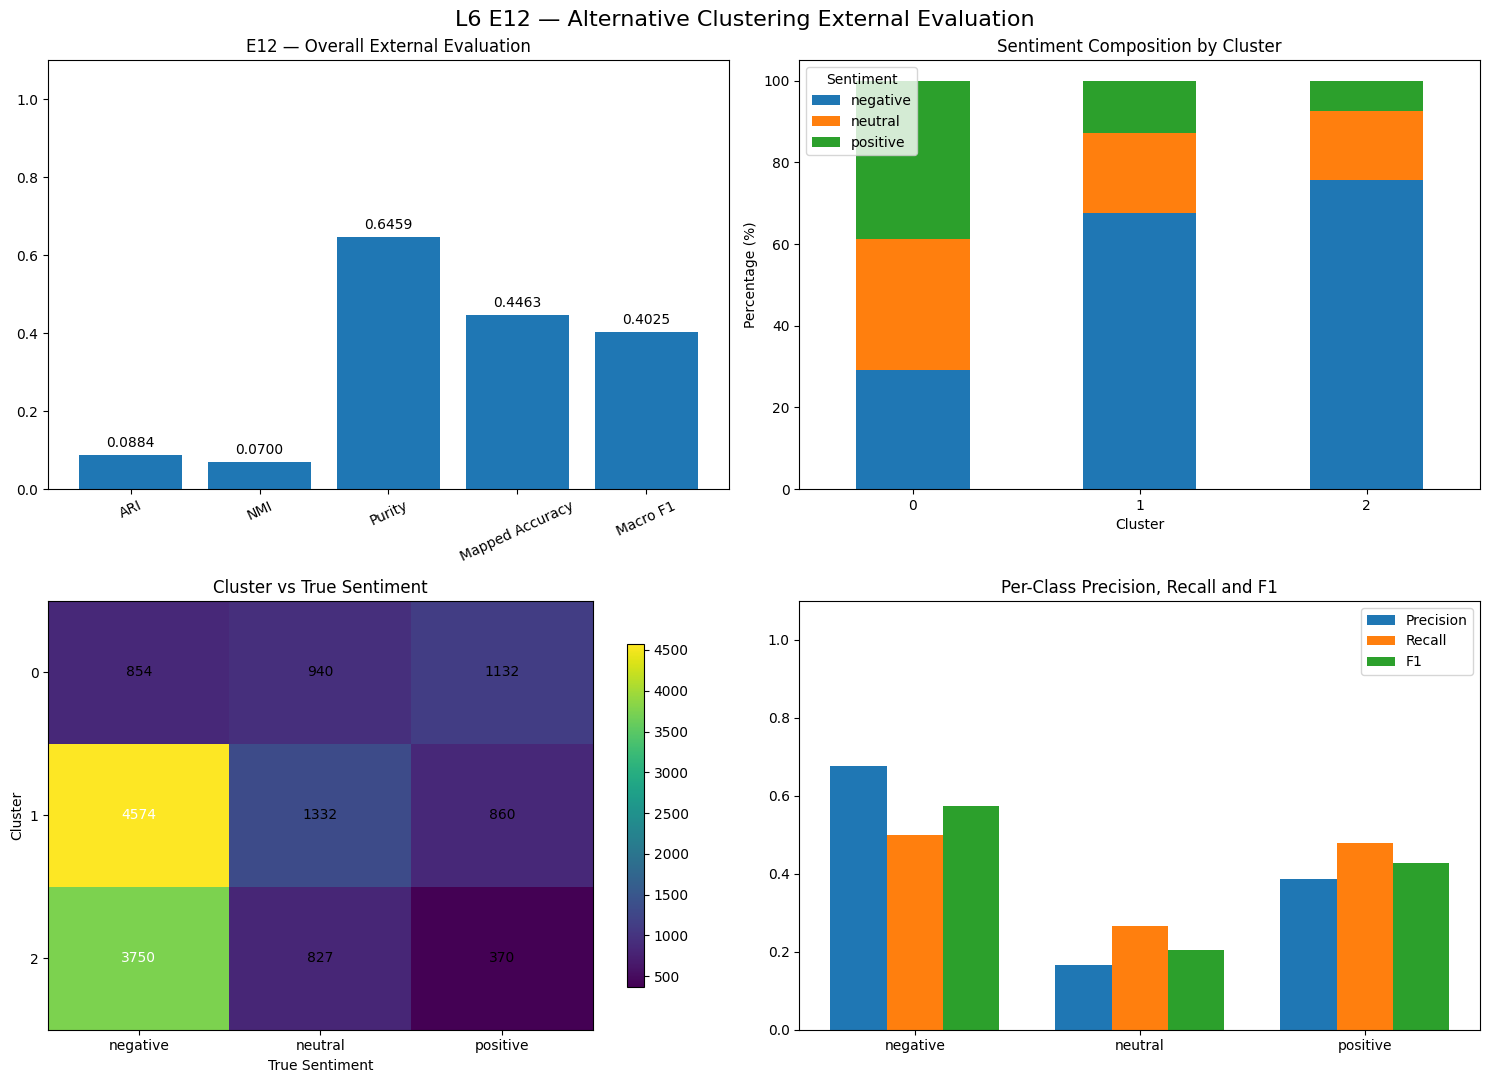


External Evaluation Summary
----------------------------------------
ARI:             0.088395
NMI:             0.069959
Purity:          0.645946
Mapped Accuracy: 0.446274
Macro F1:        0.402488

Cluster-to-sentiment mapping:
{np.int64(0): 'positive', np.int64(1): 'negative', np.int64(2): 'neutral'}

Per-class performance:


,Sentiment,Precision,Recall,F1,Support
0,negative,0.676027,0.498366,0.573758,9178
1,neutral,0.167172,0.266860,0.205568,3099
2,positive,0.386876,0.479255,0.428139,2362



Silhouette: 0.05650137573662224 (metric: euclidean )

Figure saved to: /content/drive/MyDrive/MSI5001 project/EDA/L6-externaleval/E12/figures/E12_external_evaluation.png


In [13]:
# L6 E12 — External Evaluation Visualizations (Updated)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment
from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score,
    precision_recall_fscore_support
)

# Existing notebook variables
y_true = np.asarray(labels)
cluster_labels = np.asarray(y_pred)

classes = ["negative", "neutral", "positive"]
clusters = sorted(np.unique(cluster_labels))

assert len(y_true) == len(cluster_labels) == 14639
assert set(np.unique(y_true)) == set(classes)
assert len(clusters) == 3

# Contingency matrix
ct = pd.crosstab(
    pd.Series(cluster_labels, name="Cluster"),
    pd.Series(y_true, name="Sentiment")
).reindex(index=clusters, columns=classes, fill_value=0)

# Optimal one-to-one cluster-to-sentiment mapping
rows, cols = linear_sum_assignment(-ct.to_numpy())

mapping = {
    ct.index[r]: ct.columns[c]
    for r, c in zip(rows, cols)
}

y_mapped = np.array([mapping[c] for c in cluster_labels])

# Evaluation metrics
ari = adjusted_rand_score(y_true, cluster_labels)
nmi = normalized_mutual_info_score(y_true, cluster_labels)
purity = ct.max(axis=1).sum() / ct.to_numpy().sum()
accuracy = np.mean(y_mapped == y_true)

precision, recall, f1, support = precision_recall_fscore_support(
    y_true,
    y_mapped,
    labels=classes,
    zero_division=0
)

macro_f1 = float(np.mean(f1))

# Four visualization panels
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# 1. Overall metrics, including Macro F1
metric_names = [
    "ARI", "NMI", "Purity",
    "Mapped Accuracy", "Macro F1"
]
metric_values = [ari, nmi, purity, accuracy, macro_f1]

bars = axes[0, 0].bar(metric_names, metric_values)
axes[0, 0].set_title("E12 — Overall External Evaluation")
axes[0, 0].set_ylim(0, 1.1)
axes[0, 0].tick_params(axis="x", rotation=25)

for bar, value in zip(bars, metric_values):
    axes[0, 0].text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.02,
        f"{value:.4f}",
        ha="center"
    )

# 2. Sentiment composition
composition = ct.div(ct.sum(axis=1), axis=0) * 100

composition.plot(
    kind="bar",
    stacked=True,
    ax=axes[0, 1]
)

axes[0, 1].set_title("Sentiment Composition by Cluster")
axes[0, 1].set_ylabel("Percentage (%)")
axes[0, 1].set_xlabel("Cluster")
axes[0, 1].tick_params(axis="x", rotation=0)
axes[0, 1].legend(title="Sentiment")

# 3. Contingency matrix
im = axes[1, 0].imshow(ct.to_numpy(), aspect="auto")
axes[1, 0].set_title("Cluster vs True Sentiment")
axes[1, 0].set_xticks(range(len(classes)), classes)
axes[1, 0].set_yticks(range(len(clusters)), clusters)
axes[1, 0].set_xlabel("True Sentiment")
axes[1, 0].set_ylabel("Cluster")

for i in range(len(clusters)):
    for j in range(len(classes)):
        value = ct.iloc[i, j]
        axes[1, 0].text(
            j, i, str(value),
            ha="center",
            va="center",
            color="white" if value > ct.to_numpy().max()/2
            else "black"
        )

fig.colorbar(im, ax=axes[1, 0], shrink=0.8)

# 4. Per-class Precision, Recall and F1
x = np.arange(len(classes))
width = 0.25

axes[1, 1].bar(x-width, precision, width, label="Precision")
axes[1, 1].bar(x, recall, width, label="Recall")
axes[1, 1].bar(x+width, f1, width, label="F1")

axes[1, 1].set_xticks(x, classes)
axes[1, 1].set_ylim(0, 1.1)
axes[1, 1].set_title("Per-Class Precision, Recall and F1")
axes[1, 1].legend()

fig.suptitle(
    "L6 E12 — Alternative Clustering External Evaluation",
    fontsize=16
)

plt.tight_layout()

# Save figure
figure_dir = OUTPUT_DIR / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)

figure_path = figure_dir / "E12_external_evaluation.png"
fig.savefig(figure_path, dpi=200, bbox_inches="tight")
plt.show()

# Numerical summary
print("\nExternal Evaluation Summary")
print("-" * 40)
print(f"ARI:             {ari:.6f}")
print(f"NMI:             {nmi:.6f}")
print(f"Purity:          {purity:.6f}")
print(f"Mapped Accuracy: {accuracy:.6f}")
print(f"Macro F1:        {macro_f1:.6f}")

print("\nCluster-to-sentiment mapping:")
print(mapping)

print("\nPer-class performance:")
display(pd.DataFrame({
    "Sentiment": classes,
    "Precision": precision,
    "Recall": recall,
    "F1": f1,
    "Support": support
}))

print("\nSilhouette:", metrics["silhouette_2000"], "(metric:", SILHOUETTE_METRIC, ")")
print("\nFigure saved to:", figure_path)